## A prototype model for identifying key mutations for FIPV/FECV switch

### 1. Minimum implementation of GWAS-like statistical test

In [3]:
import pandas as pd
import numpy as np
from Bio import SeqIO
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact
from matplotlib.font_manager import FontProperties
import matplotlib as mpl
mpl.rcParams['svg.fonttype'] = 'none'
arial_font_path = '/Users/skawakubo/python/fonts/Arial.ttf'
arial_font = FontProperties(fname=arial_font_path)
mpl.rcParams['font.family'] = arial_font.get_name()
import matplotlib.pyplot as plt

In [4]:
meta = pd.read_csv("FCoV_all_full_meta_250818_modified.tsv", sep="\t")
meta

,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,Source,Note,FECV_or_FIPV
0,NC_002306.3,79-1146,NaN,USA,NaN,NaN,29355.0,NCBI,NaN,unknown
1,PP254206.1,ZD/22/332i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV
2,PP254207.1,ZD/22/337i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV
3,PP254208.1,ZD/22/385i,2022/7/19,India,Felis catus,feces,29286.0,NCBI,NaN,FECV
4,PP254209.1,ZD/22/519i,2022/7/21,India,Felis catus,feces,29221.0,NCBI,NaN,FECV
...,...,...,...,...,...,...,...,...,...,...
157,FECV43,FECV43,2025/6/16,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV
158,FECV46,FECV46,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV
159,FECV47,FECV47,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV
160,FECV51,FECV51,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV


In [5]:
# load protien alignment
ids = []
seqs = []

for rec in SeqIO.parse("al_FCoV1_144comp_S_aa_modified.fas", "fasta"):
    ids.append(rec.id)
    seqs.append(str(rec.seq))

df_fasta = pd.DataFrame({"ID": ids, "Seq": seqs})
df_fasta

,ID,Seq
0,KY566209.1,MILLLLAFFSVVKSQDAPHGVTLPQF---------NTSHNNDKFEL...
1,PP254206.1,MIVLILALLSTASSRDAPNGVTLPHF---------NTSYNNAKFEL...
2,PP254207.1,MIVLIFALLSTVRALDAPHGVXTPLF---------NTSNDNDKFEL...
3,PP254208.1,MIVLJXALLSTXSSNDAPXGXTLPHF---------NTXYNNAKFEL...
4,PP254209.1,MILLLXALLSVXSSEDAPHGAXLPHF---------NTSHNNHKFEL...
...,...,...
139,FECV47,MIVLILALLSTVRSEDAPHGVTLPQF---------NTSYNSQKFEL...
140,FECV5,MILLLLTFLTAVRSEDAPHGVTLPQF---------NTSHNNDKFEL...
141,FECV51,MIV-LLALLTVVRSEDAPHGAILPHF---------NTSHNNTKFEL...
142,FECV66,MIV-LLALLTVVRSEDAPHGAILPHF---------NTSHNNTKFEL...


In [6]:
df_fasta['X_count'] = df_fasta['Seq'].str.count('X')
df_fasta

,ID,Seq,X_count
0,KY566209.1,MILLLLAFFSVVKSQDAPHGVTLPQF---------NTSHNNDKFEL...,0
1,PP254206.1,MIVLILALLSTASSRDAPNGVTLPHF---------NTSYNNAKFEL...,106
2,PP254207.1,MIVLIFALLSTVRALDAPHGVXTPLF---------NTSNDNDKFEL...,4
3,PP254208.1,MIVLJXALLSTXSSNDAPXGXTLPHF---------NTXYNNAKFEL...,133
4,PP254209.1,MILLLXALLSVXSSEDAPHGAXLPHF---------NTSHNNHKFEL...,15
...,...,...,...
139,FECV47,MIVLILALLSTVRSEDAPHGVTLPQF---------NTSYNSQKFEL...,0
140,FECV5,MILLLLTFLTAVRSEDAPHGVTLPQF---------NTSHNNDKFEL...,0
141,FECV51,MIV-LLALLTVVRSEDAPHGAILPHF---------NTSHNNTKFEL...,0
142,FECV66,MIV-LLALLTVVRSEDAPHGAILPHF---------NTSHNNTKFEL...,0


In [7]:
df_merged = pd.merge(meta, df_fasta, how="inner", left_on="Accession", right_on="ID")
df_merged

,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,Source,Note,FECV_or_FIPV,ID,Seq,X_count
0,PP254206.1,ZD/22/332i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,PP254206.1,MIVLILALLSTASSRDAPNGVTLPHF---------NTSYNNAKFEL...,106
1,PP254207.1,ZD/22/337i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,PP254207.1,MIVLIFALLSTVRALDAPHGVXTPLF---------NTSNDNDKFEL...,4
2,PP254208.1,ZD/22/385i,2022/7/19,India,Felis catus,feces,29286.0,NCBI,NaN,FECV,PP254208.1,MIVLJXALLSTXSSNDAPXGXTLPHF---------NTXYNNAKFEL...,133
3,PP254209.1,ZD/22/519i,2022/7/21,India,Felis catus,feces,29221.0,NCBI,NaN,FECV,PP254209.1,MILLLXALLSVXSSEDAPHGAXLPHF---------NTSHNNHKFEL...,15
4,PP254210.1,ZD/22/561i,2022/7/22,India,Felis catus,feces,29199.0,NCBI,NaN,FECV,PP254210.1,MIVLLLALISVANTEDAPHGVTLPXF---------NTSHDNEXFEL...,44
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,FECV43,FECV43,2025/6/16,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,FECV43,MIVLLLALLSTAKSHDAPHGVTLPQF---------NTSHNNDKFEL...,0
140,FECV46,FECV46,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,FECV46,MIVLLLVLLSTAKSHDAPHGVTLPQF---------NTSYNNDKFEL...,0
141,FECV47,FECV47,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,FECV47,MIVLILALLSTVRSEDAPHGVTLPQF---------NTSYNSQKFEL...,0
142,FECV51,FECV51,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,FECV51,MIV-LLALLTVVRSEDAPHGAILPHF---------NTSHNNTKFEL...,0


In [12]:
df_merged_filtered = df_merged[df_merged['X_count'] < 100]
# replace 'FECV' in 'FECV_or_FIPV' with '0' and 'FIPV' with '1' and 'unknown' with '' for better encoding
df_merged_filtered['FECV_or_FIPV_encodes'] = df_merged_filtered['FECV_or_FIPV'].replace({'FECV': '0', 'FIPV': '1', 'unknown': ''})
df_merged_filtered

/var/folders/nj/8kpvd8913_q3ctwwtzf2lr_00000gn/T/ipykernel_67109/2301268783.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_merged_filtered['FECV_or_FIPV_encodes'] = df_merged_filtered['FECV_or_FIPV'].replace({'FECV': '0', 'FIPV': '1', 'unknown': ''})


,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,Source,Note,FECV_or_FIPV,ID,Seq,X_count,FECV_or_FIPV_encodes
1,PP254207.1,ZD/22/337i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,PP254207.1,MIVLIFALLSTVRALDAPHGVXTPLF---------NTSNDNDKFEL...,4,0
3,PP254209.1,ZD/22/519i,2022/7/21,India,Felis catus,feces,29221.0,NCBI,NaN,FECV,PP254209.1,MILLLXALLSVXSSEDAPHGAXLPHF---------NTSHNNHKFEL...,15,0
4,PP254210.1,ZD/22/561i,2022/7/22,India,Felis catus,feces,29199.0,NCBI,NaN,FECV,PP254210.1,MIVLLLALISVANTEDAPHGVTLPXF---------NTSHDNEXFEL...,44,0
6,PP254212.1,ZD/22/639i,2022/7/23,India,Felis catus,feces,29265.0,NCBI,NaN,FECV,PP254212.1,MIVLILALLSTAKSQDAPNGVTLPHF---------NTSYNNAKFEL...,6,0
7,PP254213.1,ZD/22/719i,2022/8/23,India,Felis catus,lung,29224.0,NCBI,NaN,FIPV,PP254213.1,MIVLIFALLSTVSSEDAPHGVKLPQF---------NTSNDNSKFEL...,34,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,FECV43,FECV43,2025/6/16,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,FECV43,MIVLLLALLSTAKSHDAPHGVTLPQF---------NTSHNNDKFEL...,0,0
140,FECV46,FECV46,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,FECV46,MIVLLLVLLSTAKSHDAPHGVTLPQF---------NTSYNNDKFEL...,0,0
141,FECV47,FECV47,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,FECV47,MIVLILALLSTVRSEDAPHGVTLPQF---------NTSYNSQKFEL...,0,0
142,FECV51,FECV51,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,FECV51,MIV-LLALLTVVRSEDAPHGAILPHF---------NTSHNNTKFEL...,0,0


In [15]:
df_selected = df_merged_filtered[['Accession', 'Seq', 'FECV_or_FIPV_encodes']]
df_selected = df_selected[df_selected['FECV_or_FIPV_encodes'] != '']
df_selected.rename(columns={'FECV_or_FIPV_encodes': 'FIP_label'}, inplace=True)
df_selected.reset_index(drop=True, inplace=True)
df_selected

,Accession,Seq,FIP_label
0,PP254207.1,MIVLIFALLSTVRALDAPHGVXTPLF---------NTSNDNDKFEL...,0
1,PP254209.1,MILLLXALLSVXSSEDAPHGAXLPHF---------NTSHNNHKFEL...,0
2,PP254210.1,MIVLLLALISVANTEDAPHGVTLPXF---------NTSHDNEXFEL...,0
3,PP254212.1,MIVLILALLSTAKSQDAPNGVTLPHF---------NTSYNNAKFEL...,0
4,PP254213.1,MIVLIFALLSTVSSEDAPHGVKLPQF---------NTSNDNSKFEL...,1
5,PP908788.1,MIVLLLALLSTASSEDAPHGVTLPQF---------NTSHNNDKFEL...,0
6,PP908789.1,MIVLLLAMLGVVNTQDAPHGVTLPQF---------NTSNDNRFFEL...,0
7,PP854701.1,MIVLVLALLGSVRSDDAPHGVTLPQF---------NTSNNNERFEL...,1
8,PP854702.1,MIVLVLALLGSVRSDDAPHGVTLPQF---------NTSNNNERFEL...,1
9,ON595853.1,MI-LLFALLAIVKSEDAPHGVTLPQF---------NTSHNNAKFEL...,0


In [25]:
seqs = df_selected["Seq"].tolist()
y = df_selected["FIP_label"].to_numpy(int)

L = len(df_selected['Seq'][0])

records = []
for pos in range(L):
    col = np.array([s[pos] for s in seqs])
    # reference amino acid
    uniq, counts = np.unique(col, return_counts=True)
    ref = uniq[np.argmax(counts)]
    for aa in uniq:
        if aa == ref:
            continue
        aa_mask = (col == aa)
        # 2×2： [aa∩case, aa∩control; not_aa∩case, not_aa∩control]
        a = int(np.sum(aa_mask & (y==1)))
        b = int(np.sum(aa_mask & (y==0)))
        c = int(np.sum((~aa_mask) & (y==1)))
        d = int(np.sum((~aa_mask) & (y==0)))
        # odds ratio calculation
        OR = (a*d+1e-9)/((b*c)+1e-9)
        _, p = fisher_exact([[a,b],[c,d]], alternative="two-sided")
        records.append({"mutation": f"pos{pos+1:04d}_{aa}",
                        "pos": pos+1, "aa": aa, "ref": ref,
                        "a_case":a,"b_ctrl":b,"c_case_not":c,"d_ctrl_not":d,
                        "OR": OR, "p": p})

res = pd.DataFrame(records)
# multiple test correction
res["q"] = multipletests(res["p"], method="fdr_bh")[1]
# summarize per site
site_summary = (res.groupby("pos")
                  .agg(min_q=("q","min"),
                       max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v+1e-9))))))
                  .reset_index()
                  .sort_values(["min_q","max_abs_logOR"])).reset_index(drop=True)

In [23]:
res

,mutation,pos,aa,ref,a_case,b_ctrl,c_case_not,d_ctrl_not,OR,p,q
0,pos0002_M,2,M,I,1,0,19,31,3.100000e+10,0.392157,0.529127
1,pos0003_-,3,-,V,1,9,19,22,1.286550e-01,0.067303,0.529127
2,pos0003_I,3,I,V,0,1,20,30,5.000000e-11,1.000000,1.000000
3,pos0003_L,3,L,V,10,6,10,25,4.166667e+00,0.031444,0.529127
4,pos0003_W,3,W,V,0,3,20,28,1.666667e-11,0.270588,0.529127
...,...,...,...,...,...,...,...,...,...,...,...
3804,pos1896_-,1896,-,I,1,0,19,31,3.100000e+10,0.392157,0.529127
3805,pos1896_F,1896,F,I,2,0,18,31,6.200000e+10,0.149020,0.529127
3806,pos1896_V,1896,V,I,2,2,18,29,1.611111e+00,0.640256,0.816450
3807,pos1897_-,1897,-,H,1,0,19,31,3.100000e+10,0.392157,0.529127


In [26]:
site_summary

,pos,min_q,max_abs_logOR
0,1380,0.000620,26.722202
1,707,0.529127,0.855382
2,5,0.529127,1.203973
3,897,0.529127,1.517323
4,673,0.529127,1.666596
...,...,...,...
1680,962,1.000000,20.674476
1681,963,1.000000,20.674476
1682,978,1.000000,20.674476
1683,979,1.000000,20.674476


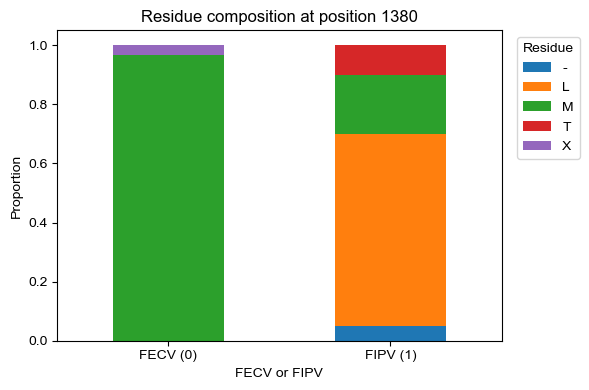

In [30]:
pos = 1380  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()